# Análise de Viés Algorítmico em Seleção de Candidatos (XAI)
### Etapa 2: Treinamento e Avaliação do Modelo

Usaremos um **Random Forest** para prever `Best Match` (aprovado/reprovado).

Objetivo desta etapa: obter um modelo com desempenho razoável, já que nosso foco é a explicabilidade

## 1. Importar bibliotecas e carregar os dados pré-processados

In [1]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

PASTA_DADOS = 'dados'

X_train = pd.read_csv(os.path.join(PASTA_DADOS, 'X_train.csv'), index_col=0)
X_test = pd.read_csv(os.path.join(PASTA_DADOS, 'X_test.csv'), index_col=0)
y_train = pd.read_csv(os.path.join(PASTA_DADOS, 'y_train.csv'), index_col=0).squeeze()
y_test = pd.read_csv(os.path.join(PASTA_DADOS, 'y_test.csv'), index_col=0).squeeze()

print('X_train:', X_train.shape, '| X_test:', X_test.shape)

X_train: (8000, 54) | X_test: (2000, 54)


## 2. Treinar o modelo

Parâmetros iniciais simples (`n_estimators=100` árvores, `random_state=42` para reprodutibilidade). É adicionado o `max_depth=10` pois sem ele, as árvores do random forest ficam tão complexas que o cálculo exato do SHAP fica extremamente lento.

In [2]:
modelo = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
modelo.fit(X_train, y_train)

print('Modelo treinado com sucesso.')

Modelo treinado com sucesso.


## 3. Avaliar o desempenho no conjunto de teste

In [3]:
y_pred = modelo.predict(X_test)

acuracia = accuracy_score(y_test, y_pred)
precisao = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f'Acurácia:  {acuracia:.3f}')
print(f'Precisão:  {precisao:.3f}')
print(f'Recall:    {recall:.3f}')
print(f'F1-Score:  {f1:.3f}')
print()
print(classification_report(y_test, y_pred, target_names=['Não aprovado', 'Aprovado']))

Acurácia:  0.771
Precisão:  0.789
Recall:    0.723
F1-Score:  0.754

              precision    recall  f1-score   support

Não aprovado       0.76      0.82      0.79      1030
    Aprovado       0.79      0.72      0.75       970

    accuracy                           0.77      2000
   macro avg       0.77      0.77      0.77      2000
weighted avg       0.77      0.77      0.77      2000



## 4. Matriz de confusão

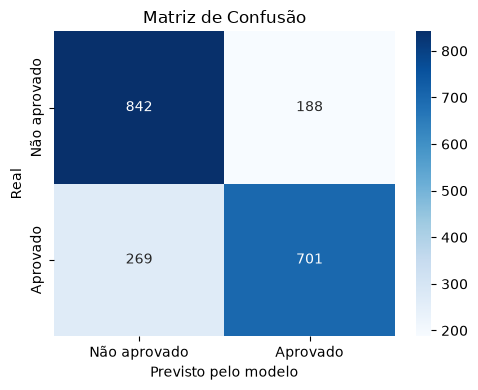

In [4]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Não aprovado', 'Aprovado'],
            yticklabels=['Não aprovado', 'Aprovado'])
plt.xlabel('Previsto pelo modelo')
plt.ylabel('Real')
plt.title('Matriz de Confusão')
plt.tight_layout()
plt.savefig(os.path.join(PASTA_DADOS, 'matriz_confusao.png'), dpi=150)
plt.show()

## 5. Importância das variáveis (visão geral, antes do SHAP)

O Random Forest já fornece uma medida simples de importância de variáveis (`feature_importances_`). Isso ainda não é o SHAP (que vem na próxima etapa e é mais preciso/interpretável), mas já dá um primeiro indício de quais variáveis mais pesam nas decisões do modelo.

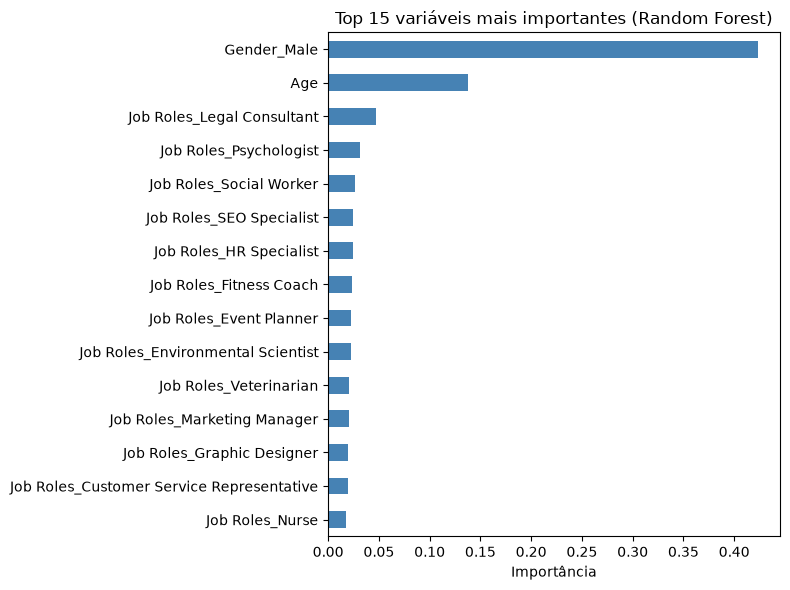

Gender_Male                                  0.423925
Age                                          0.137475
Job Roles_Legal Consultant                   0.046675
Job Roles_Psychologist                       0.031713
Job Roles_Social Worker                      0.026032
Job Roles_SEO Specialist                     0.024937
Job Roles_HR Specialist                      0.024372
Job Roles_Fitness Coach                      0.023011
Job Roles_Event Planner                      0.022767
Job Roles_Environmental Scientist            0.022133
Job Roles_Veterinarian                       0.021004
Job Roles_Marketing Manager                  0.020883
Job Roles_Graphic Designer                   0.019601
Job Roles_Customer Service Representative    0.019421
Job Roles_Nurse                              0.017790
dtype: float64


In [5]:
importancias = pd.Series(modelo.feature_importances_, index=X_train.columns)
top15 = importancias.sort_values(ascending=False).head(15)

plt.figure(figsize=(8,6))
top15.sort_values().plot(kind='barh', color='steelblue')
plt.title('Top 15 variáveis mais importantes (Random Forest)')
plt.xlabel('Importância')
plt.tight_layout()
plt.savefig(os.path.join(PASTA_DADOS, 'importancia_variaveis.png'), dpi=150)
plt.show()

print(top15)

## 6. Salvar o modelo treinado

In [6]:
joblib.dump(modelo, os.path.join(PASTA_DADOS, 'modelo_random_forest.pkl'))
print('Modelo salvo em dados/modelo_random_forest.pkl')

Modelo salvo em dados/modelo_random_forest.pkl
